Координаты ФЭУ:
[[ 0.16104292 -0.41420427  1.95      ]
 [-0.68149594  0.33624883  1.85      ]
 [ 0.92965601  0.27062835  1.75      ]
 [-0.58680971 -0.96599915  1.65      ]
 [-0.24582308  1.23978668  1.55      ]
 [ 1.11026824 -0.8153554   1.45      ]
 [-1.46700571 -0.15935574  1.35      ]
 [ 1.03059575  1.17276272  1.25      ]
 [ 0.03381154 -1.63595745  1.15      ]
 [-1.17551271  1.23112544  1.05      ]
 [ 1.7560378  -0.11760632  0.95      ]
 [-1.41365664 -1.13096194  0.85      ]
 [ 0.28514784  1.83199091  0.75      ]
 [ 1.04794238 -1.57458463  0.65      ]
 [-1.86688081  0.46071252  0.55      ]
 [ 1.71045773  0.9337207   0.45      ]
 [-0.63712583 -1.86321515  0.35      ]
 [-0.79486636  1.81815496  0.25      ]
 [ 1.82344773 -0.80779847  0.15      ]
 [-1.89495994 -0.63767297  0.05      ]
 [ 0.96654259  1.75022725 -0.05      ]
 [ 0.46838698 -1.93858547 -0.15      ]
 [-1.64652748  1.1074508  -0.25      ]
 [ 1.94716312  0.29335263 -0.35      ]
 [-1.22478689 -1.51571669 -0.45      ]
 [-0.1191

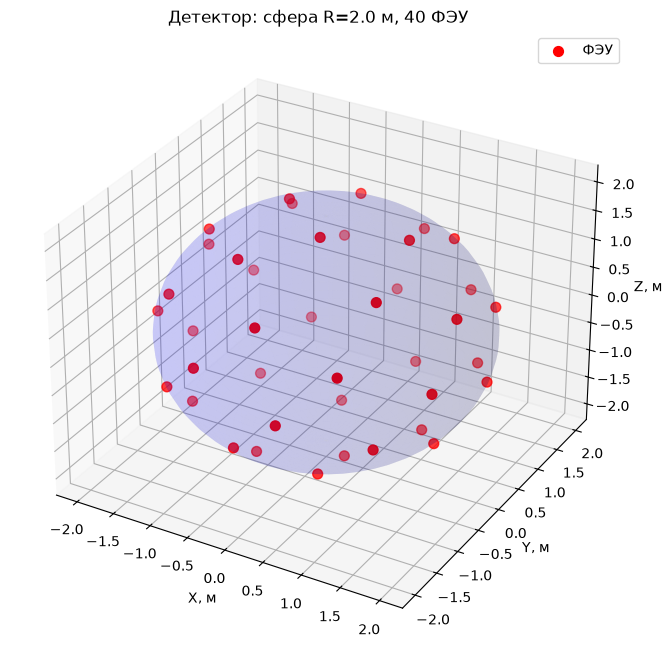

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmt_positions = self._generate_pmt_positions()

    def _generate_pmt_positions(self):
        indices = np.arange(0, self.N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / self.N)
        theta = np.pi * (1 + 5**0.5) * indices
        
        x = np.cos(theta) * np.sin(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(phi)
        
        return np.column_stack([x * self.R, y * self.R, z * self.R])

    def contains_point(self, point):
        point = np.asarray(point, dtype=float)
        distances = np.linalg.norm(self.pmt_positions - point, axis=1)
        min_dist = np.min(distances)
        if min_dist <= self.r:
            return int(np.argmin(distances))
        return -1

    def visualize(self):
        fig = plt.figure(figsize=(8, 8))
        ax = fig.add_subplot(111, projection='3d')

        u = np.linspace(0, 2 * np.pi, 50)
        v = np.linspace(0, np.pi, 50)
        x = self.R * np.outer(np.cos(u), np.sin(v))
        y = self.R * np.outer(np.sin(u), np.sin(v))
        z = self.R * np.outer(np.ones(np.size(u)), np.cos(v))
        ax.plot_surface(x, y, z, color='b', alpha=0.1, edgecolor='none')

        ax.scatter(self.pmt_positions[:, 0],
                   self.pmt_positions[:, 1],
                   self.pmt_positions[:, 2],
                   color='red', s=50, label='ФЭУ')

        ax.set_xlabel('X, м')
        ax.set_ylabel('Y, м')
        ax.set_zlabel('Z, м')
        ax.set_title(f'Детектор: сфера R={self.R} м, {self.N} ФЭУ')
        ax.legend()
        plt.show()


det = Detector(R=2.0, N=40, r=0.1, a=0.5)
print("Координаты ФЭУ:")
print(det.pmt_positions[:40])

test_point = det.pmt_positions[5]
idx = det.contains_point(test_point)
if idx == -1:
    print(f"Точка {test_point}: не попал в ФЭУ")
else:
    print(f"Точка {test_point}: попал в ФЭУ номер {idx}")

test_point2 = np.array([0, 0, 1])
idx2 = det.contains_point(test_point2)
if idx2 == -1:
    print(f"Точка {test_point2}: не попал в ФЭУ")
else:
    print(f"Точка {test_point2}: попал в ФЭУ номер {idx2}")

det.visualize()